# Groq-Powered Visual Browser Automation Agent

This notebook converts the original Alfred / Wayne Manor browser-automation script into a notebook workflow using:

- **smolagents `CodeAgent`** for the agent loop
- **Groq's OpenAI-compatible API** through `OpenAIServerModel`
- **Helium + Selenium** for browser control
- **WebSearchTool** for web search
- **Pillow** for capturing browser screenshots and passing them back to the agent

The agent searches for Wonder Woman, visits relevant pages (including Wikipedia), inspects screenshots, and produces a visual description.

> **Model note:** This notebook uses `qwen/qwen3.8-27b`, matching the model ID you tested with the Groq SDK. The model and Groq endpoint must support image input for screenshot-based visual reasoning. If Groq reports that the model is unavailable or does not accept images, use a currently available Groq vision model and update `GROQ_MODEL` below.


## 1. Install dependencies

In [61]:
%pip install -U "smolagents[openai]" helium selenium pillow python-dotenv


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Load environment variables

In [62]:
from dotenv import load_dotenv
import os

load_dotenv()

GROQ_API_KEY = os.getenv("GROQ_API_KEY")
GROQ_MODEL = os.getenv("GROQ_MODEL", "qwen/qwen3.8-27b")

if not GROQ_API_KEY:
    raise ValueError(
        "GROQ_API_KEY was not found. Add it to your .env file or environment."
    )

print("Groq API key loaded:", bool(GROQ_API_KEY))
print("Model:", GROQ_MODEL)

Groq API key loaded: True
Model: groq/openai/gpt-oss-120b


Create a `.env` file in the same directory as this notebook:

```env
GROQ_API_KEY=gsk_your_actual_key
GROQ_MODEL=qwen/qwen3.8-27b
```

Do not paste your real API key into a notebook cell or commit the `.env` file to GitHub.


## 3. Imports and model configuration

In [63]:
from io import BytesIO
from time import sleep

import helium
from PIL import Image
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys

from smolagents import CodeAgent, OpenAIServerModel, WebSearchTool, tool
from smolagents.agents import ActionStep

model = OpenAIServerModel(
    model_id="qwen/qwen3.8-27b",
    api_base="https://api.groq.com/openai/v1",
    api_key=os.getenv("GROQ_API_KEY"),
    temperature=0.1,
    max_tokens=2048
)

print(f"Configured model: {GROQ_MODEL}")

Configured model: groq/openai/gpt-oss-120b


## 4. Define the browser task

In [64]:
alfred_guest_list_request = """
I am Alfred, the butler of Wayne Manor, responsible for verifying the identity
of guests at a party. A superhero has arrived at the entrance claiming to be
Wonder Woman, but I need to confirm whether she is who she says she is.

Search the web for reliable images of Wonder Woman and develop a detailed
visual description based on the images. Navigate to Wikipedia to gather
relevant information about her commonly depicted appearance.

Summarize distinguishing visual characteristics, such as costume, colors,
accessories, hairstyle, and other recognizable details. Clearly distinguish
well-established character traits from variations across adaptations.
Do not claim that a real person in a photo is Wonder Woman; this task is
to describe the fictional character's commonly depicted appearance.
"""

## 5. Initialize Chrome

In [65]:
def initialize_driver():
    """Start a visible Chrome browser controlled by Helium/Selenium."""
    chrome_options = webdriver.ChromeOptions()
    chrome_options.add_argument("--force-device-scale-factor=1")
    chrome_options.add_argument("--window-size=1200,1000")
    chrome_options.add_argument("--disable-pdf-viewer")
    chrome_options.add_argument("--window-position=0,0")

    return helium.start_chrome(
        headless=False,
        options=chrome_options,
    )


# Start the browser once. If you rerun this cell, close the previous
# browser first using the cleanup cell at the end of the notebook.
driver = initialize_driver()
print("Chrome browser started.")

Chrome browser started.


## 6. Define browser tools

In [66]:
@tool
def search_item_ctrl_f(text: str, nth_result: int = 1) -> str:
    """
    Find visible page elements containing the requested text and scroll to
    the nth match.

    Args:
        text: Text to search for on the current page.
        nth_result: One-based occurrence number; defaults to 1.
    """
    if nth_result < 1:
        raise ValueError("nth_result must be 1 or greater.")

    # Use XPath string literals safely, including text containing apostrophes.
    if "'" not in text:
        xpath_text = f"'{text}'"
    elif '"' not in text:
        xpath_text = f'"{text}"'
    else:
        parts = text.split("'")
        xpath_text = "concat(" + ', "\'", '.join(
            f"'{part}'" for part in parts
        ) + ")"

    elements = driver.find_elements(
        By.XPATH,
        f"//*[contains(normalize-space(string(.)), {xpath_text})]"
    )

    if nth_result > len(elements):
        return (
            f"Match {nth_result} not found; "
            f"only {len(elements)} matches were found for {text!r}."
        )

    element = elements[nth_result - 1]
    driver.execute_script(
        "arguments[0].scrollIntoView({block: 'center'});",
        element
    )

    return (
        f"Found {len(elements)} matching elements for {text!r}. "
        f"Scrolled to match {nth_result}."
    )


@tool
def go_back() -> str:
    """Navigate back to the previous browser page."""
    driver.back()
    return "Navigated back one page."


@tool
def close_popups() -> str:
    """Send Escape to dismiss a visible modal or popup when possible."""
    webdriver.ActionChains(driver).send_keys(Keys.ESCAPE).perform()
    return "Sent Escape to the active browser window." 

## 7. Capture screenshots after agent steps

In [67]:
def save_screenshot(memory_step: ActionStep, agent: CodeAgent) -> None:
    """Attach the current browser screenshot and URL to the agent step."""
    if driver is None:
        return

    sleep(1.0)  # Allow page transitions and animations to settle.

    current_step = memory_step.step_number

    # Keep only recent screenshots in agent memory to limit context size.
    for previous_step in agent.memory.steps:
        if (
            isinstance(previous_step, ActionStep)
            and previous_step.step_number <= current_step - 2
        ):
            previous_step.observations_images = None

    try:
        png_bytes = driver.get_screenshot_as_png()
        screenshot = Image.open(BytesIO(png_bytes)).convert("RGB")
        print(f"Captured browser screenshot: {screenshot.size} pixels")
        memory_step.observations_images = [screenshot.copy()]

        url_info = f"Current URL: {driver.current_url}"
        if memory_step.observations:
            memory_step.observations += "\n" + url_info
        else:
            memory_step.observations = url_info

    except Exception as exc:
        print(f"Screenshot capture failed: {exc}")

## 8. Configure the CodeAgent

In [68]:
def initialize_agent(model):
    """Create the browser-using CodeAgent."""
    return CodeAgent(
        tools=[
            WebSearchTool(),
            go_back,
            close_popups,
            search_item_ctrl_f,
        ],
        model=model,
        additional_authorized_imports=["helium", "time"],
        step_callbacks=[save_screenshot],
        max_steps=2,
        verbosity_level=2,
    )


agent = initialize_agent(model)
print("CodeAgent initialized.")

CodeAgent initialized.


## 9. Give the agent browser instructions

The agent can use Helium commands such as `go_to`, `click`, `Link`, `Text`,
`scroll_down`, and `scroll_up`. It should use `WebSearchTool` for searching
and Helium for navigating pages. It should inspect the browser screenshot
after each action and avoid logging into websites.


In [69]:
helium_instructions = """
UUse the web_search Python function to search the web.

IMPORTANT:
- You are operating as a CodeAgent.
- Generate Python code for tool execution.
- Do not attempt native API function/tool calls.
- Call tools as Python functions inside your generated code.

Example:

results = web_search("Wonder Woman official costume images")
print(results)

Then use Helium to navigate the relevant websites.

The browser is already started and managed. The following import has already
been executed in the agent's Python environment:
    from helium import *

You can navigate to a page:
    go_to("https://en.wikipedia.org/wiki/Wonder_Woman")

You can click visible text:
    click("Appearance")

Or click a link:
    click(Link("Wonder Woman"))

If an element is not found, inspect the latest screenshot and try a different
approach. After each browser action, pause and inspect the updated screenshot.

To scroll:
    scroll_down(num_pixels=900)
    scroll_up(num_pixels=500)

To dismiss a popup:
    close_popups()

You may use search_item_ctrl_f(text, nth_result=1) to find text on the page,
and go_back() to return to the previous page.

Proceed in multiple small steps. Use reliable sources and distinguish the
character's usual design from adaptation-specific differences.

When you have enough evidence, return a concise but detailed final answer
using:
    final_answer("YOUR ANSWER HERE")

Do not log into websites, submit forms, or make purchases.
"""

## 10. Run the agent

In [70]:
# Make Helium's browser helpers available inside the agent's Python executor.
agent.python_executor("from helium import *")

prompt = alfred_guest_list_request + helium_instructions

response = agent.run(prompt)
print(response)

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ I am Alfred, the butler of Wayne Manor, responsible for verifying the identity                                  │
│ of guests at a party. A superhero has arrived at the entrance claiming to be                                    │
│ Wonder Woman, but I need to confirm whether she is who she says she is.                                         │
│                                                                                                                 │
│ Search the web for reliable images of Wonder Woman and develop a detailed                                       │
│ visual description based on the images. Navigate to Wikipedia to gather                                         │
│ relevant information about her commonly depicted appearance.                                                    │
│                                                                                                                 │
│ Summarize distinguishing visual characteristics, such as costume, colors,                                       │
│ accessories, hairstyle, and other recognizable details. Clearly distinguish                                     │
│ well-established character traits from variations across adaptations.                                           │
│ Do not claim that a real person in a photo is Wonder Woman; this task is                                        │
│ to describe the fictional character's commonly depicted appearance.                                             │
│                                                                                                                 │
│ UUse the web_search Python function to search the web.                                                          │
│                                                                                                                 │
│ IMPORTANT:                                                                                                      │
│ - You are operating as a CodeAgent.                                                                             │
│ - Generate Python code for tool execution.                                                                      │
│ - Do not attempt native API function/tool calls.                                                                │
│ - Call tools as Python functions inside your generated code.                                                    │
│                                                                                                                 │
│ Example:                                                                                                        │
│                                                                                                                 │
│ results = web_search("Wonder Woman official costume images")                                                    │
│ print(results)                                                                                                  │
│                                                                                                                 │
│ Then use Helium to navigate the relevant websites.                                                              │
│                                                                                                                 │
│ The browser is already started and managed. The following import has already                                    │
│ been executed in the agent's Python environment:                                                                │
│     from helium import *                                                                                        │
│                                                       

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

Output message of the LLM: ────────────────────────────────────────────────────────────────────────────────────────
Thought: Let me start by searching the web for Wonder Woman's appearance and costume details, and also navigate to 
Wikipedia for more information.                                                                                    
<code>                                                                                                             
results = web_search("Wonder Woman costume appearance visual description")                                         
print(results)                                                                                                     
                                                                                                                   

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  results = web_search("Wonder Woman costume appearance visual description")                                       
  print(results)                                                                                                   
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Execution logs:
## Search Results

[Wonder Woman Costume 101: Complete Cosplay Guide - 
EyeCandys](https://eyecandys.com/blogs/news/wonder-woman-cosplay)
Learn how to create the ultimate Wonder  Woman  costume with this complete guide. From her signature bodice and 
tiara to her sword, shield, and makeup, we cover all the elements you need for a heroic cosplay.

[Wonder Woman's Complete Costume History - Her Best Costumes 
Ever](https://screenrant.com/wonder-woman-costume-best-costume-history-outfit/)
For over 80 years, Wonder  Woman has been one of DC Comics' most prominent superheroes, with a vast rogues gallery,
a cast of compelling supporting characters, and, like all superheroes, a vast array of costumes . Wonder  Woman's 
primary outfit has changed significantly over the decades, often reflecting both the in-universe lore and 
real-world sensibilities of its respective era, though ...

[Wonder Woman Costume Guide: How to Build the 
Look](https://www.superheroine-costume.com/wonder-woman-costume-guide-how-to-build-the-look)
Build a Wonder  Woman  costume with our guide to bodysuits, skirts, boots, tiaras, bracers, belts, capes, fit and 
sizing for cosplay.

[Wonder Woman Costume & Cosplay Guide - Halloween 2026](https://www.costumerealm.com/dress-like-wonder-woman/)
Dress like Wonder  Woman with her iconic armor, tiara, and sword. A complete Halloween costume and cosplay guide 
for DC's legendary Amazonian warrior.

[Wonder Woman Costumes: The Evolution of a Superheroine 
[Infographic]](https://www.halloweencostumes.com/blog/p-928-wonder-woman-costumes-the-evolution-of-a-superheroine-i
nfographic.aspx)
We've assembled this infographic about Wonder  Woman  costumes as a visual reference to all of her historic looks. 
With her costumes from comic books, television, and the silver screen, this comprehensive infographic has all of 
her classic looks in an easy to reference guide that will have you ready for her appearance in Superman v Batman 
and the brand new Wonder  Woman movie!

[Wonder Woman Costume Guide: Classic Looks 
(2026)](https://www.costume-shop.com/blogs/costume-marketing-center/wonder-woman-costume-guide-classic-deluxe-looks
-2026)
The complete Wonder  Woman  costume guide — silhouette breakdown, accessories, and sizing for kids, teens, and 
adults building the Amazonian look.

[Wonder Woman - Young Justice Wiki](https://youngjustice.fandom.com/wiki/Wonder_Woman)
 Wonder  Woman is a noticeably tall and fair-skinned woman with straight waist-length black hair, blue eyes, and 
broad shoulders. She is ageless and attractive in appearance , sporting a slender and athletic frame with a 
well-toned yet muscular build.

[See how Wonder Woman's costumes changed through the years](https://ew.com/books/wonder-woman-costumes-evolution/)
Illustration by LÆMEUR for EW Following the release of Wonder  Woman 1984, we looked back at how Wonder  Woman's 
style has evolved from her first appearance in the '40s to her latest comics redesign.

[10 Greatest Wonder Woman Costumes, Ranked - Screen 
Rant](https://screenrant.com/best-wonder-woman-comic-costumes-list/)
A hybrid between the traditional Wonder  Woman  costume and the Golden Eagle Armor, this ironclad design also 
features a striking red and white cape, along with a pair of starry armbands that reference Donna's Troia identity.

[A Visual History of Wonder Woman's Costumes - 
IGN](https://www.ign.com/articles/2017/05/30/a-visual-history-of-wonder-womans-costumes)
We trace the evolution of Wonder  Woman's iconic costume across DC's comics, TV shows, games and movies.

Out: None

Captured browser screenshot: (1200, 664) pixels


... (7 outputs left out)

Reached max steps.

Captured browser screenshot: (1200, 664) pixels


[Step 3: Duration 52.36 seconds| Input tokens: 11,096 | Output tokens: 257]

Thought: I'm on the Wikipedia page for Wonder Woman. I need to scroll down to find the "Appearance" section which should have detailed information about her visual characteristics. Let me scroll down to find it.
<code>
scroll_down(num_pixels=1500)
</code>
Calling tools:
[{'id': 'call_3', 'type': 'function', 'function': {'name': 'python_interpreter', 'arguments': 'scroll_down(num_pixels=1500)'}}]


## 11. Optional: inspect the current browser

Run this cell to print the current page URL. You can also use the screenshot
display to inspect the browser manually.


Current URL: https://en.wikipedia.org/wiki/Wonder_Woman


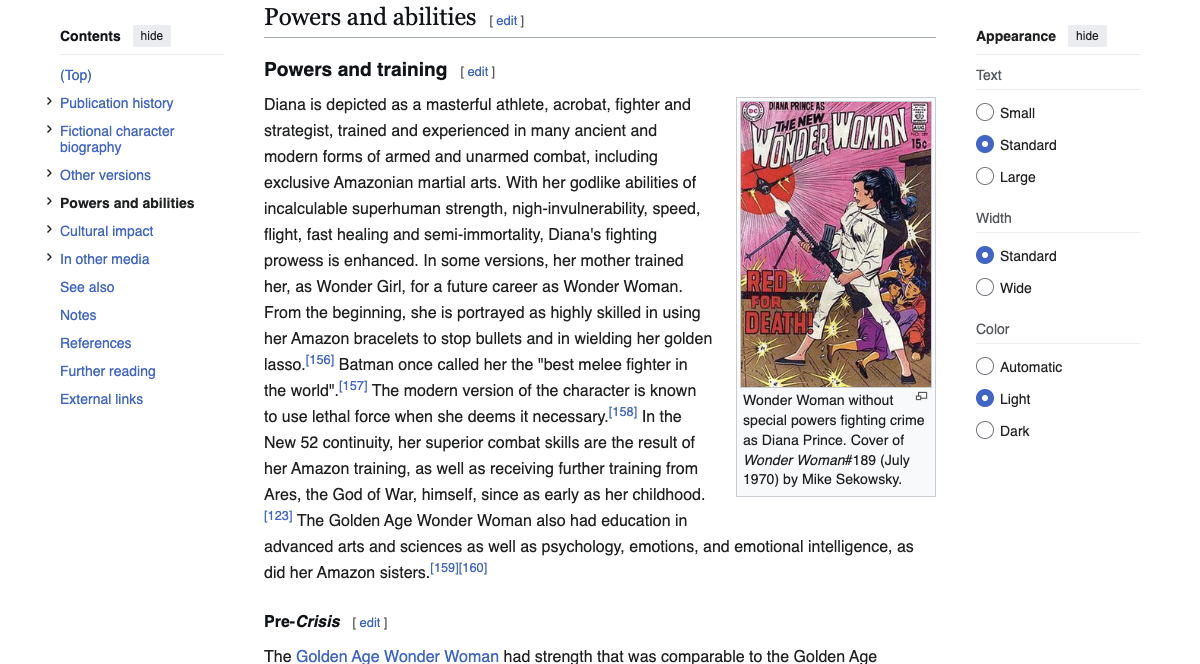

In [71]:
from IPython.display import display

if driver is not None:
    print("Current URL:", driver.current_url)
    display(Image.open(BytesIO(driver.get_screenshot_as_png())))

## 12. Close the browser when finished

In [72]:
# Run this cell when you are completely finished.
if driver is not None:
    try:
        helium.kill_browser()
        print("Browser closed.")
    except Exception as exc:
        print(f"Could not close browser cleanly: {exc}")

Browser closed.
